This notebook is for LSTM modelling.

In [1]:
# import libraries
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
# set global colors and styles
sns.set_palette('Blues_d')

# 1. Load data

In [3]:
data = pd.read_csv('capstone_outsourcing_df.csv')

In [4]:
data.head()

,services,payment_date,payment_amount
0,CONTRACTOR COSTS,2015-07-14,4.801811
1,CONTRACTOR COSTS,2015-07-21,10.156949
2,CONTRACTOR COSTS,2015-07-28,4.493026
3,CONTRACTOR COSTS,2015-08-04,9.553150
4,CONTRACTOR COSTS,2015-08-11,5.237410


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1859 entries, 0 to 1858
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   services        1859 non-null   object 
 1   payment_date    1859 non-null   object 
 2   payment_amount  1859 non-null   float64
dtypes: float64(1), object(2)
memory usage: 43.7+ KB


In [6]:
# change the datatype of payment_date
data['payment_date'] = pd.to_datetime(data['payment_date'], format = '%Y-%m-%d', errors = 'coerce')

In [7]:
# check the date range
period_start = data.payment_date.min()
period_end = data.payment_date.max()

print(f"The DataFrame starts on {period_start} and ends on {period_end}")

The DataFrame starts on 2015-07-14 00:00:00 and ends on 2026-06-29 00:00:00


In [8]:
# create a full date list for the DataFrame
full_date = pd.date_range(start = period_start, end = period_end, freq = 'D')

# create a list of unique descriptions
desc_list = data['services'].unique()

# create a multi-index list
idx = pd.MultiIndex.from_product( [full_date, desc_list], names = ['payment_date', 'services'])

# cross join the DataFrame with date gaps and the full date list
full_df = data.set_index( ['payment_date', 'services']).reindex(idx).reset_index()
full_df = full_df.fillna(0)
full_df.head()

,payment_date,services,payment_amount
0,2015-07-14,CONTRACTOR COSTS,4.801811
1,2015-07-14,LABOUR HIRE COSTS,6.248572
2,2015-07-15,CONTRACTOR COSTS,0.000000
3,2015-07-15,LABOUR HIRE COSTS,0.000000
4,2015-07-16,CONTRACTOR COSTS,0.000000


In [9]:
# create a copy DataFrame
df = full_df.copy()
df.shape

(8008, 3)

In [10]:
# pivot the DataFrame to make 'CONTRACTOR' and 'LABOUR' separate columns
df_pivot = df.pivot_table(
        index="payment_date", columns="services", values="payment_amount"
    ).fillna(0)

In [11]:
df_pivot

services,CONTRACTOR COSTS,LABOUR HIRE COSTS
payment_date,,
2015-07-14,4.801811,6.248572
2015-07-15,0.000000,0.000000
2015-07-16,0.000000,0.000000
2015-07-17,0.000000,0.000000
2015-07-18,0.000000,0.000000
...,...,...
2026-06-25,11.100341,5.268845
2026-06-26,0.000000,0.000000
2026-06-27,0.000000,0.000000


In [12]:
len(df_pivot)

4004

In [13]:
df_pivot.index[3204]

Timestamp('2024-04-21 00:00:00')

In [14]:
# convert df_pivot from DataFrame to a Numpy array
df_array = df_pivot.to_numpy()

In [15]:
# create rolling monthly windows
time_steps = 30 #using the past week to predict
X, y = [], []
for i in range(len(df_pivot) - time_steps):
    X.append(df_array[i : i + time_steps])
    y.append(df_array[i + time_steps])

X, y = np.array(X), np.array(y)

# 2. train/test split (80/20)

In [16]:
# split

train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"X_train Shape: {X_train.shape} -> (Samples, Time Steps, 2 Features)")
print(f"y_train Shape: {y_train.shape} -> (Samples, 2 Target Features)")

X_train Shape: (3179, 30, 2) -> (Samples, Time Steps, 2 Features)
y_train Shape: (3179, 2) -> (Samples, 2 Target Features)


In [17]:
total_samples = len(y_train) + len(y_test)
print(f"Total samples y: {total_samples} with training of {len(y_train)} and test of {len(y_test)}.")

Total samples y: 3974 with training of 3179 and test of 795.


In [18]:
lookback_offset = len(df_pivot) - total_samples
print(f"Lookback offset is {lookback_offset}.")

Lookback offset is 30.


In [19]:
# extract dates corresponding to the test rows
start_test_idx = lookback_offset + len(y_train)
print(start_test_idx)

test_dates = df_pivot.index[start_test_idx : start_test_idx + len(y_test)]
print(test_dates)

3209
DatetimeIndex(['2024-04-26', '2024-04-27', '2024-04-28', '2024-04-29',
               '2024-04-30', '2024-05-01', '2024-05-02', '2024-05-03',
               '2024-05-04', '2024-05-05',
               ...
               '2026-06-20', '2026-06-21', '2026-06-22', '2026-06-23',
               '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27',
               '2026-06-28', '2026-06-29'],
              dtype='datetime64[ns]', name='payment_date', length=795, freq=None)


In [20]:
X_train[0]

array([[ 4.80181106,  6.2485722 ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [10.15694906,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 4.49302577,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 9.55315038,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 0.        ,  0.        ],
       [ 5.23740961,

In [21]:
y_train[0]

array([0., 0.])

# 3. LSTM Model

In [22]:
# define Model Hyperparameters

input_time_steps = X_train.shape[1]  # E.g., 30 days
input_features = X_train.shape[2]  # 2 features (Contractor & Labour Hire)
output_features = y_train.shape[1]  # 2 target values to predict

In [23]:
# build the LSTM architecture
model = Sequential(
    [
        # first LSTM layer requires explicit input_shape
        # return_sequences=True is needed only if stacking another LSTM layer next
        LSTM(
            64,
            activation="relu",
            input_shape=(input_time_steps, input_features),
            return_sequences=False,
        ),
        # dropout helps prevent overfitting on smaller transaction datasets
        Dropout(0.2),
        # dense layer outputs the predictions for both categories simultaneously
        Dense(output_features),
    ]
)

In [24]:
# compile the Model
# 'adam' optimizer balances training speed and stability
# Mean Squared Error (MSE) is the standard loss metric for continuous values
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,282 (67.51 KB)

 Trainable params: 17,282 (67.51 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# train the Model
# validation_data evaluates performance on unseen test data after each epoch
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1,
)

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 22.9297 - mae: 2.8352 - val_loss: 21.0343 - val_mae: 3.2625
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 20.1457 - mae: 2.9977 - val_loss: 19.4073 - val_mae: 3.0368
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 16.9471 - mae: 2.6926 - val_loss: 13.8368 - val_mae: 2.2108
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 12.5449 - mae: 2.2018 - val_loss: 10.6221 - val_mae: 1.9317
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 10.9032 - mae: 1.9793 - val_loss: 10.9030 - val_mae: 1.7279
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 10.3169 - mae: 1.8504 - val_loss: 10.2108 - val_mae: 1.6412
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.9506 - mae: 1.7504 - val_loss: 9.9943 - val_mae: 1.6720
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.7558 - mae: 1.7252 - val_loss: 10.5793 - val_mae: 1.5809
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [26]:
# Predict on test data
predictions = model.predict(X_test)

y_test_actual = y_test

# Quick view of predicted vs actual for the first test sample
print(f"Predicted Costs (Contractor, Labour): {predictions[0]}")
print(f"Actual Costs (Contractor, Labour): {y_test_actual[0]}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Predicted Costs (Contractor, Labour): [3.825538  0.5941742]
Actual Costs (Contractor, Labour): [0. 0.]


# 4. Evaluate LSTM Predictions

In [27]:
# separate the columns for individual evaluation
# column 0 = Contractor Costs, column 1 = Labour Hire Costs
pred_contractor, pred_labour = predictions[:, 0], predictions[:, 1]
act_contractor, act_labour = y_test[:, 0], y_test[:, 1]

In [28]:
def print_metrics(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"=== Evaluation Metrics for {model_name} ===")
    print(f"Mean Absolute Error (MAE):     {mae:,.2f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
    print(f"R² Score (Variance Explained):  {r2:.4f}")
    print("-" * 45)


# Print performance scores
print_metrics(act_contractor, pred_contractor, "Contractor Costs")
print_metrics(act_labour, pred_labour, "Labour Hire Costs")

=== Evaluation Metrics for Contractor Costs ===
Mean Absolute Error (MAE):     2.40
Root Mean Squared Error (RMSE): 4.70
R² Score (Variance Explained):  0.1489
---------------------------------------------
=== Evaluation Metrics for Labour Hire Costs ===
Mean Absolute Error (MAE):     1.44
Root Mean Squared Error (RMSE): 3.17
R² Score (Variance Explained):  0.3981
---------------------------------------------


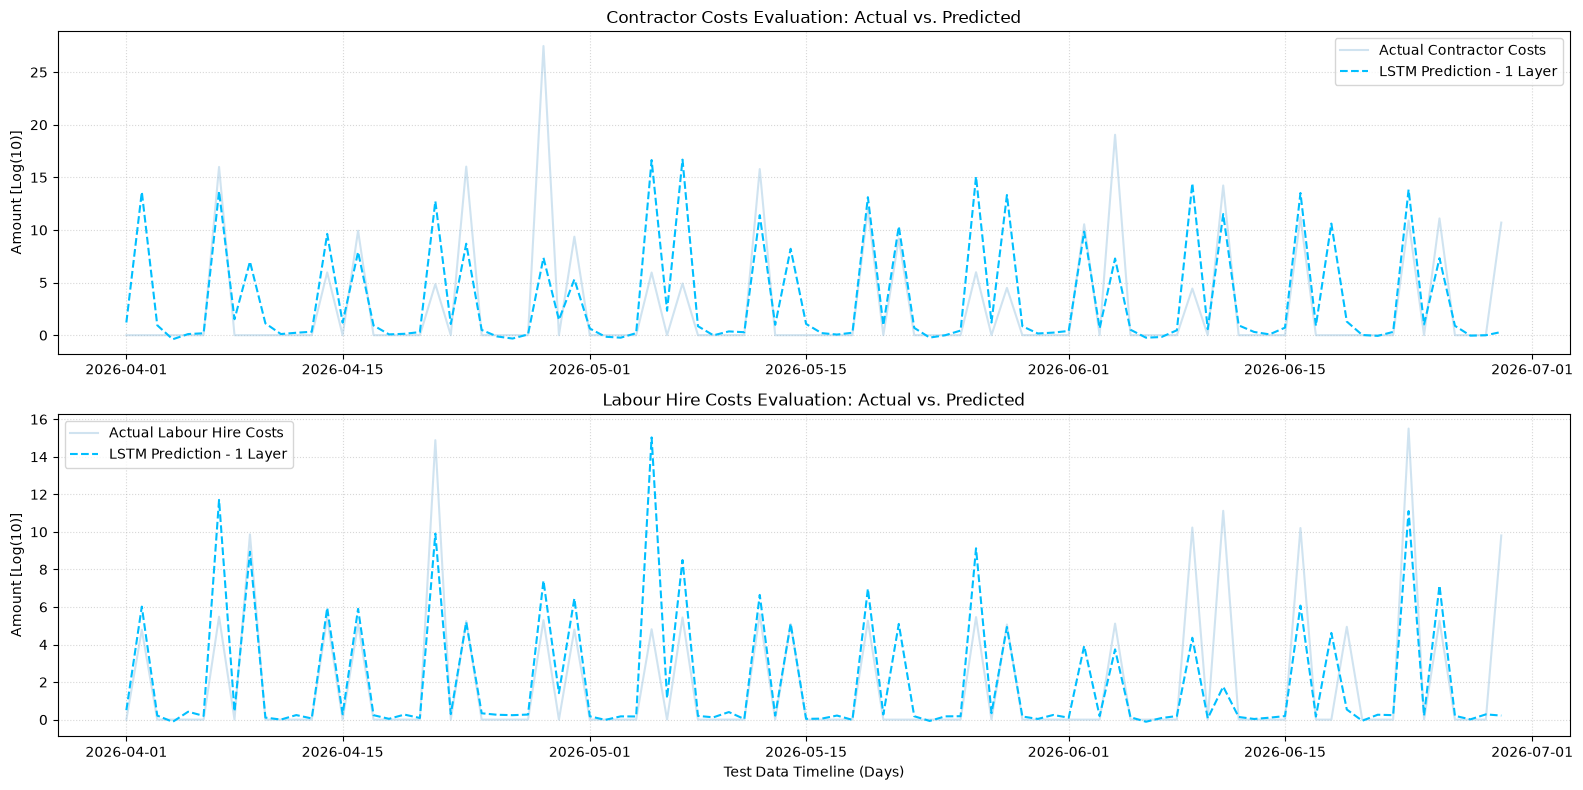

In [29]:
n = 90 # number of days to show

plt.figure(figsize=(16, 8))

# subplot 1: Contractor Costs forecast
plt.subplot(2, 1, 1)
plt.plot(
    test_dates[-n:],
    act_contractor[-n:],
    label="Actual Contractor Costs",
    alpha=0.4,
    linewidth=1.5,
)
plt.plot(
    test_dates[-n:],
    pred_contractor[-n:],
    label="LSTM Prediction - 1 Layer",
    color="deepskyblue",
    linestyle="--",
    linewidth=1.5,
)
plt.title("Contractor Costs Evaluation: Actual vs. Predicted")
plt.ylabel("Amount [Log(10)]")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)

# subplot 2: Labour Hire Costs forecast
plt.subplot(2, 1, 2)
plt.plot(
    test_dates[-n:],
    act_labour[-n:],
    label="Actual Labour Hire Costs",
    alpha=0.4,
    linewidth=1.5,
)
plt.plot(
    test_dates[-n:],
    pred_labour[-n:],
    label="LSTM Prediction - 1 Layer",
    color="deepskyblue",
    linestyle="--",
    linewidth=1.5,
)
plt.title("Labour Hire Costs Evaluation: Actual vs. Predicted")
plt.xlabel("Test Data Timeline (Days)")
plt.ylabel("Amount [Log(10)]")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()


In [30]:
lstm_model = keras.Sequential()
lstm_model.add(layers.Input(shape=(input_time_steps, input_features))) 
lstm_model.add(layers.LSTM(32, return_sequences = True))
lstm_model.add(layers.Dropout(0.2))
lstm_model.add(layers.LSTM(16, return_sequences=False))
lstm_model.add(layers.Dense(output_features))


lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 30, 32)         │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,650 (29.88 KB)

 Trainable params: 7,650 (29.88 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
lstm_model.fit(X_train, y_train, 
               epochs=50,
                batch_size=32,
                validation_data=(X_test, y_test),
                verbose=1)

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 22.0946 - val_loss: 21.4456
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 20.4329 - val_loss: 20.9516
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 19.6602 - val_loss: 20.6552
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 18.8296 - val_loss: 18.8215
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 17.9046 - val_loss: 18.2498
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 16.9201 - val_loss: 16.5071
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 15.7579 - val_loss: 16.2302
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 14.7417 - val_loss: 13.7866
Epoch 9/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 13.2589 - val_loss: 13.2025
Epoch 10/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 12.0134 - val_loss: 12.0452
Epoch 11/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 11.1636 - val_loss: 11.4410
Epoch 12/50
100/100 ━━━━━━━━━━

In [32]:
# Predict on test data
predictions2 = lstm_model.predict(X_test)


# Quick view of predicted vs actual for the first test sample
print(f"Predicted Costs (Contractor, Labour): {predictions2[0]}")
print(f"Actual Costs (Contractor, Labour): {y_test[0]}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Predicted Costs (Contractor, Labour): [1.6423892 0.8450288]
Actual Costs (Contractor, Labour): [0. 0.]


In [33]:
pred_contractor2, pred_labour2 = predictions2[:, 0], predictions2[:, 1]
act_contractor2, act_labour2 = y_test[:, 0], y_test[:, 1]

In [34]:
# Print performance scores
print_metrics(act_contractor2, pred_contractor2, "Contractor Costs")
print_metrics(act_labour2, pred_labour2, "Labour Hire Costs")

=== Evaluation Metrics for Contractor Costs ===
Mean Absolute Error (MAE):     2.06
Root Mean Squared Error (RMSE): 3.85
R² Score (Variance Explained):  0.4265
---------------------------------------------
=== Evaluation Metrics for Labour Hire Costs ===
Mean Absolute Error (MAE):     1.15
Root Mean Squared Error (RMSE): 2.56
R² Score (Variance Explained):  0.6087
---------------------------------------------


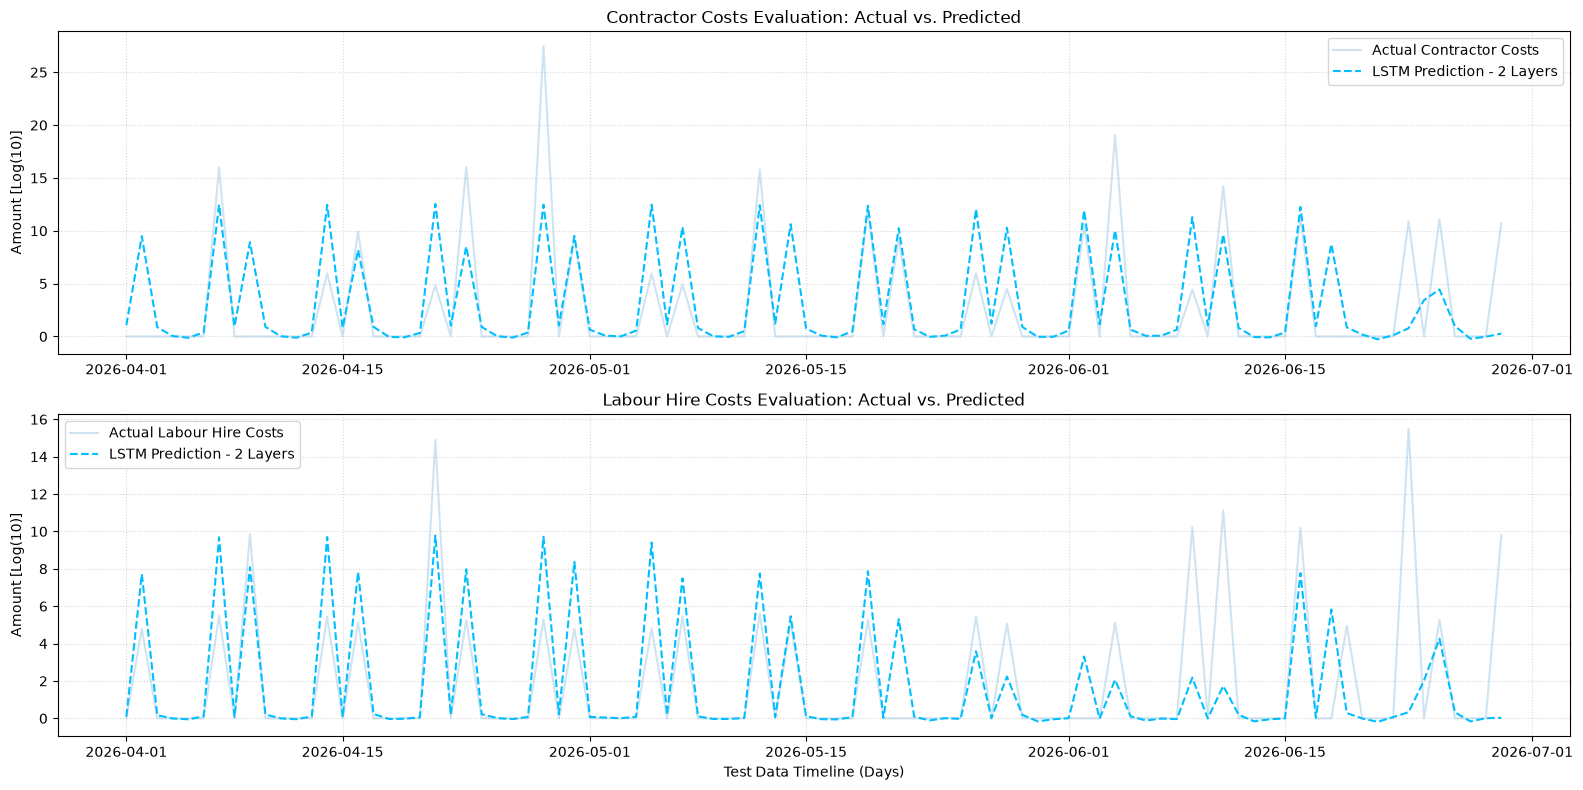

In [35]:
plt.figure(figsize=(16, 8))

# subplot 1: Contractor Costs forecast
plt.subplot(2, 1, 1)
plt.plot(
    test_dates[-n:],
    act_contractor2[-n:],
    label="Actual Contractor Costs",
    alpha=0.4,
    linewidth=1.5,
)
plt.plot(
    test_dates[-n:],
    pred_contractor2[-n:],
    label="LSTM Prediction - 2 Layers",
    color="deepskyblue",
    linestyle="--",
    linewidth=1.5,
)
plt.title("Contractor Costs Evaluation: Actual vs. Predicted")
plt.ylabel("Amount [Log(10)]")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)

# subplot 2: Labour Hire Costs forecast
plt.subplot(2, 1, 2)
plt.plot(
    test_dates[-n:],
    act_labour2[-n:],
    label="Actual Labour Hire Costs",
    alpha=0.4,
    linewidth=1.5,
)
plt.plot(
    test_dates[-n:],
    pred_labour2[-n:],
    label="LSTM Prediction - 2 Layers",
    color="deepskyblue",
    linestyle="--",
    linewidth=1.5,
)
plt.title("Labour Hire Costs Evaluation: Actual vs. Predicted")
plt.xlabel("Test Data Timeline (Days)")
plt.ylabel("Amount [Log(10)]")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()
